<a href="https://colab.research.google.com/github/Shreya59422/Gen-AI_Lab/blob/main/Gen_AI_Exp_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Develop an auto encoder model to reconstruct MNIST dataset

1. Importing necessary libraries:

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,Model
import matplotlib.pyplot as plt

2. Data Acquistion


In [ ]:
(x_train,_),(x_test,_) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


3. Normalization


In [ ]:
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0


4. Flattening

In [ ]:
x_train = x_train.reshape(-1,784)
x_test = x_test.reshape(-1,784)

5. Encoder Model


In [ ]:
input_img = layers.Input(shape=(784,))
encoded = layers.Dense(128,activation='relu')(input_img)
encoded = layers.Dense(32,activation='relu')(encoded)

6. Decoder

In [ ]:
decoded = layers.Dense(128,activation='relu')(encoded)
decoded = layers.Dense(784,activation='sigmoid')(decoded)

7. Create Autoencoder


In [ ]:
autoencoder = Model(input_img,decoded)

8. Compile

In [ ]:
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

9. Train


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.2291 - val_loss: 0.1499
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1342 - val_loss: 0.1205
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1164 - val_loss: 0.1105
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.1091 - val_loss: 0.1049
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1044 - val_loss: 0.1015
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1015 - val_loss: 0.0990
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0994 - val_loss: 0.0975
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0979 - val_loss: 0.0966
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0969 - val_loss: 0.0951
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0958 - val_loss: 0.0940
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


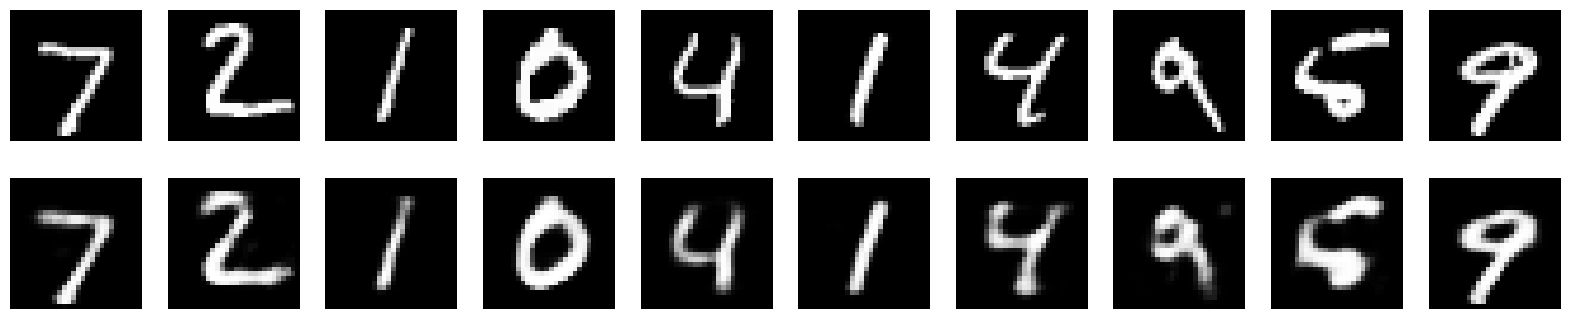

In [ ]:
autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    validation_data=(x_test, x_test)
)

# Reconstruct test images
reconstructed = autoencoder.predict(x_test)

# -------------------------
# Display original vs reconstructed
# -------------------------

n = 10

plt.figure(figsize=(20, 4))

for i in range(n):

    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()